# Projeto 3 — extração híbrida de conhecimento clínico e pacientes virtuais

**Ponto de partida.** O Projeto 2 mostrou que um classificador treinado com 413 julgamentos humanos supera as regras
do Projeto 1 (F1 0,63 → 0,75), mas deixou duas questões abertas: `CAUSED_BY` nunca foi aprendida (4 exemplos no gold)
e a hipótese, não testada, de que *para ir além das regras faltam mais julgamentos humanos, e não mais texto*.

**O que este caderno mostra**, na ordem em que o projeto foi construído:

1. **MACCROBAT** (E0): 200 relatos anotados só por humanos, convertidos para o esquema do P1.
2. **Generalização**: as etapas do P1 e do P2 medidas fora do MultiCaRe.
3. **P3-G**: o classificador do P2 aprende também com os julgamentos humanos do MACCROBAT.
4. **P3-D**: embeddings de sentença como mais uma fonte de atributos.
5. **O LLM como anotador** (E3/E4): prompts, validação por regras e autoconsistência.
6. **Paciente Virtual** (E6): perfis de diagnóstico tirados do grafo, ficha, diálogo e diagnóstico diferencial.
7. **Ida e volta**: o texto gerado volta aos extratores — e encontra um erro do P1, cuja correção é validada no
   MACCROBAT.
8. **O grafo do P3** comparado com os do P1 e do P2.

Tudo roda **sem chave de API**. Algumas células usam o gazetteer UMLS (licenciado, fora do git); sem ele, elas leem o
resultado já gravado em `data/processed/`.

## 0. Preparação

In [1]:
import collections, csv, os, sys, time
from pathlib import Path

raiz = Path.cwd()
while not (raiz / "src" / "clinical_kg").exists() and raiz != raiz.parent:
    raiz = raiz.parent
sys.path.insert(0, str(raiz / "src"))
os.chdir(raiz)

import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_colwidth", 90)

def tabela(nome, **opcoes):
    # as tabelas de resultados estão em data/processed/resultados/<avaliação>/
    return pd.read_csv(next((raiz / "data/processed/resultados").rglob(nome)), **opcoes)

from clinical_kg.hibrido.pipeline import gazetteer_disponivel
TEM_UMLS = gazetteer_disponivel()
print("raiz:", raiz.name, "| gazetteer UMLS completo:", "sim" if TEM_UMLS else "não (usa os resultados gravados)")

raiz: project3 | gazetteer UMLS completo: sim


## 1. MACCROBAT2020 no esquema do P1 (E0)

200 relatos de caso do PubMed Central, anotados à mão no formato **brat** (Caufield et al., 2019): trechos (`T`),
eventos (`E`), relações (`R`), grupos simultâneos (`*`) e atributos como a polaridade (`A`). O leitor é nosso, sem
dependências, e lê direto do zip.

In [2]:
from clinical_kg.maccrobat.brat import ler_zip
from clinical_kg.maccrobat.preparar import garantir_zip

documentos = ler_zip(garantir_zip())
doc = documentos[0]
print(f"{len(documentos)} documentos; o primeiro (PMID {doc.pmid}) começa assim:\n")
print(doc.texto[:300], "...\n")
for t in sorted(doc.trechos.values(), key=lambda t: t.inicio)[:12]:
    print(f"  {t.id:<4}{t.tipo:<22}{t.texto!r}  {doc.atributos.get(t.id, '')}")

200 documentos; o primeiro (PMID 15939911) começa assim:

CASE: A 28-year-old previously healthy man presented with a 6-week history of palpitations.
The symptoms occurred during rest, 2–3 times per week, lasted up to 30 minutes at a time and were associated with dyspnea.
Except for a grade 2/6 holosystolic tricuspid regurgitation murmur (best heard at the ...

  T1  Age                   '28-year-old'  
  T2  History               'previously healthy'  
  T5  Sign_symptom          'healthy'  
  T3  Sex                   'man'  
  T4  Clinical_event        'presented'  
  T6  Duration              '6-week'  
  T7  Sign_symptom          'palpitations'  
  T8  Coreference           'symptoms'  
  T9  Clinical_event        'rest'  
  T10 Frequency             '2–3 times per week'  
  T11 Detailed_description  'up to 30 minutes at a time'  
  T12 Sign_symptom          'dyspnea'  


O mapeamento para o P1 é feito por regras (`maccrobat/mapeamento.py`). Só duas relações têm equivalente direto e
viram rótulo de treino — `CAUSE` → `CAUSED_BY` e `MODIFY` com uma estrutura do corpo → `LOCATED_IN`. As outras são
guardadas com o seu papel (valor de exame, dose, ordem temporal, correferência), mas não rotulam pares: o MACCROBAT
não anota `TREATED_WITH` ou `REVEALED_BY`, então a ausência delas lá não quer dizer nada.

In [3]:
resumo = dict(tabela("maccrobat_resumo.csv").values.tolist())
papeis = ["CAUSED_BY", "LOCATED_IN", "VALOR_DE_EXAME", "DOSE_DE_MEDICAMENTO", "TEMPORAL", "CORREFERENCIA"]
pd.DataFrame({"papel no P3": papeis, "relações": [resumo[f"papel_{p}"] for p in papeis]})

,papel no P3,relações
0,CAUSED_BY,149
1,LOCATED_IN,3006
2,VALOR_DE_EXAME,2747
3,DOSE_DE_MEDICAMENTO,553
4,TEMPORAL,2412
5,CORREFERENCIA,795


In [4]:
comuns = pd.read_csv(raiz / "data/interim/maccrobat/maccrobat_multicare.csv")
print(f"{len(comuns)} dos 200 documentos também estão no MultiCaRe (mesmo PMID); entidades no esquema do P1: "
      f"{resumo['entidades_p1']}")

14 dos 200 documentos também estão no MultiCaRe (mesmo PMID); entidades no esquema do P1: 14351


O MACCROBAT dá o que o P1 e o P2 nunca tiveram: um gold **humano e externo**, com **149 relações causais** — 37 vezes
os 4 exemplos de `CAUSED_BY` do gold do MultiCaRe.

## 2. Generalização: o P1 e o P2 fora do MultiCaRe

Os pares candidatos são gerados sobre o MACCROBAT exatamente como no MultiCaRe (o gerador do P1), mas com as
entidades **do gold humano**, para medir só a decisão de relação.

In [5]:
externo = tabela("p3_externo_maccrobat.csv")
externo[["decisor", "tipo", "precisao", "cobertura", "f1", "anotadas", "teto_do_gerador"]]

,decisor,tipo,precisao,cobertura,f1,anotadas,teto_do_gerador
0,p1,CAUSED_BY,0.3780,0.3974,0.3875,113,0.6903
1,p1,LOCATED_IN,0.6869,0.4167,0.5187,2800,0.8064
2,p2_estrutura,CAUSED_BY,0.0370,0.0128,0.0190,113,0.6903
3,p2_estrutura,LOCATED_IN,0.7344,0.8415,0.7843,2800,0.8064
4,p2_completo,CAUSED_BY,0.0200,0.0128,0.0156,113,0.6903
5,p2_completo,LOCATED_IN,0.7242,0.8096,0.7645,2800,0.8064


* O P2 generaliza onde aprendeu: `LOCATED_IN` vai de 0,52 (regras) para 0,77.
* E desaprende onde não teve exemplos: `CAUSED_BY` cai de 0,39 para 0,02. Com 4 exemplos, o P2 não sabe o que as
  regras sabiam.
* `teto_do_gerador`: o gerador do P1 só propõe 81% dos `LOCATED_IN` e 69% dos `CAUSED_BY` anotados. Nenhum decisor
  sobre esses pares passa disso.

As outras etapas do P1 (entidades, asserção, medidas) — `make p3-etapas`:

In [6]:
entidades = tabela("p3_externo_entidades.csv")
display(entidades[entidades["modo"].isin(["exato", "exato_tipo", "sobreposicao", "sobreposicao_tipo"])
                  & (entidades["grupo"] == "TOTAL")][["modo", "gold", "previstas", "precisao", "cobertura", "f1"]])
display(tabela("p3_externo_medidas.csv")[["vinculo", "numericas", "deteccao", "acerto_vinculo_gold",
                                          "acerto_vinculo_gazetteer"]])

,modo,gold,previstas,precisao,cobertura,f1
0,exato,14383,10837,0.4936,0.3719,0.4242
6,exato_tipo,14383,10837,0.3916,0.2951,0.3366
7,sobreposicao,14383,10837,0.7711,0.5810,0.6626
13,sobreposicao_tipo,14383,10837,0.5714,0.4305,0.4910


,vinculo,numericas,deteccao,acerto_vinculo_gold,acerto_vinculo_gazetteer
0,VALOR_DE_EXAME,1173,0.5959,0.8655,0.4578
1,DOSE_DE_MEDICAMENTO,282,0.9007,0.8740,0.5945


O gargalo é **reconhecer as entidades**: o gazetteer acerta F1 0,49 mesmo aceitando sobreposição, e o vínculo valor →
exame cai de 0,87 para 0,46 quando as entidades do gold dão lugar às do gazetteer. Ligar o valor ao exame certo,
dado o exame, a regra do P1 já faz bem.

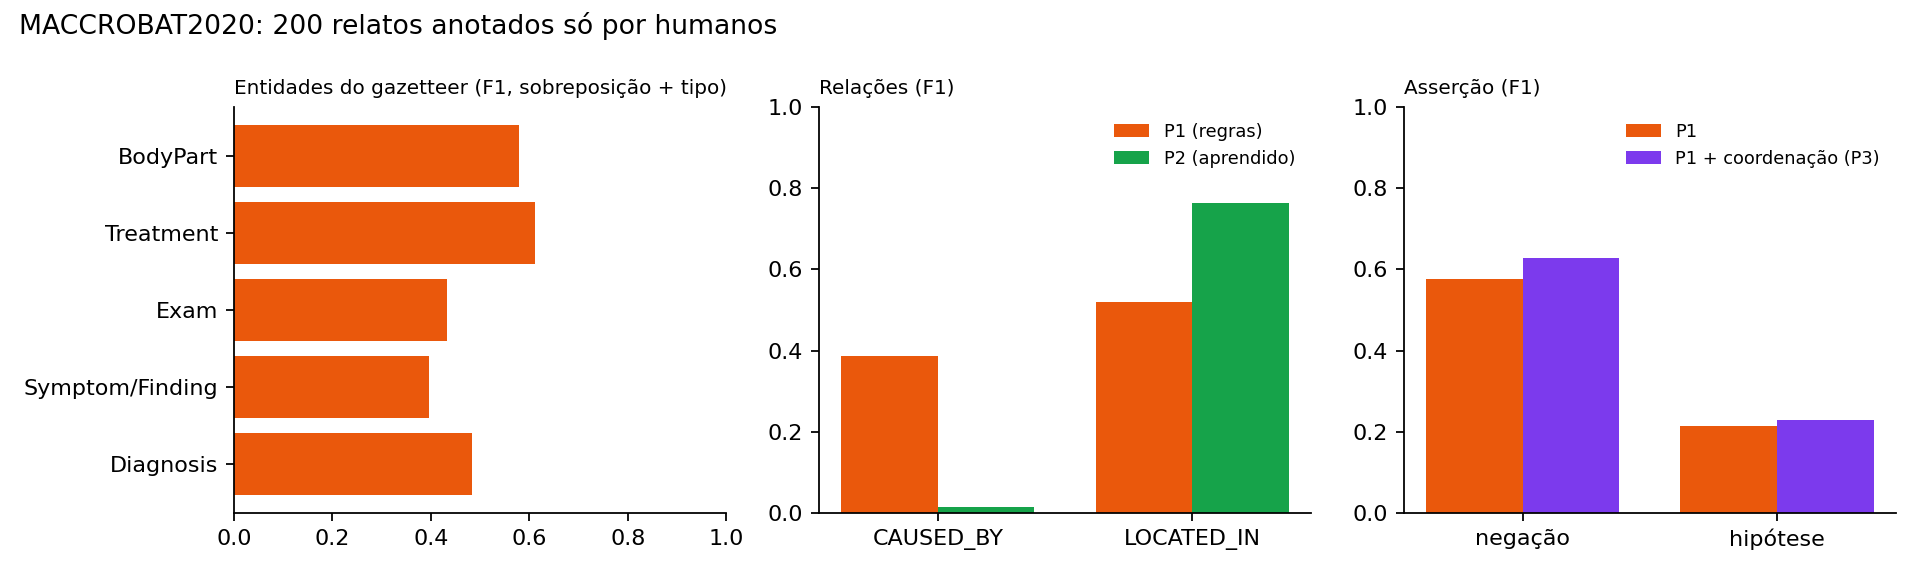

In [7]:
display(Image(filename=str(raiz / "assets/images/p3_externo_maccrobat.png"), width=900))

## 3. P3-G: mais julgamentos humanos, de outro corpus

Testa a hipótese do P2. No um-contra-todos do P2 cada relação tem o seu modelo binário; os de `CAUSED_BY` e
`LOCATED_IN` passam a treinar com **gold + pares do MACCROBAT**, e os outros seis só com o gold. Só os **rótulos**
vêm do MACCROBAT: PMI e modelo de linguagem continuam do MultiCaRe, então o efeito medido é o dos julgamentos.

O protocolo é o do P2 (deixa um caso de fora, bootstrap pareado por caso), e P1 e P2 são recalculados na mesma
execução. A célula abaixo refaz a comparação central (~1 min).

In [8]:
from clinical_kg.learning.modelo import carregar_exemplos
from clinical_kg.learning.pipeline import VARIANTES, bootstrap_pareado, medir, prever_validando, prf, textos_dos_casos
from clinical_kg.hibrido.pipeline import PROPORCAO_NEGATIVOS, carregar_maccrobat
from clinical_kg.hibrido.transferencia import balancear, contagem_por_rotulo, prever_validando_hibrido

inicio = time.time()
gold = carregar_exemplos()
textos = textos_dos_casos()
_, pares_mac, _ = carregar_maccrobat()
externos = balancear(pares_mac, PROPORCAO_NEGATIVOS)
print(f"gold: {len(gold)} pares; MACCROBAT: {len(pares_mac)} candidatos, "
      f"{dict(contagem_por_rotulo(externos))} usados no treino (1 positivo : 3 negativos)")

previsoes = {"P1": prever_validando(gold, textos, "p1"),
             "P2 completo": prever_validando(gold, textos, "completo"),
             "P3-G": prever_validando_hibrido(gold, textos, VARIANTES["completo"], externos)}
resultados = {n: medir(p) for n, p in previsoes.items()}
pd.DataFrame([{"variante": n, "precisão": round(m["p"], 3), "cobertura": round(m["r"], 3), "F1": round(m["f1"], 3),
               "tipo certo": round(m["tipo"], 3)} for n, m in resultados.items()])

gold: 413 pares; MACCROBAT: 10643 candidatos, {'LOCATED_IN': 2258, 'CAUSED_BY': 78, 'NENHUMA': 7008} usados no treino (1 positivo : 3 negativos)


,variante,precisão,cobertura,F1,tipo certo
0,P1,0.602,0.656,0.628,0.772
1,P2 completo,0.687,0.833,0.753,0.913
2,P3-G,0.682,0.873,0.766,0.886


In [9]:
r = bootstrap_pareado(resultados["P3-G"]["contagem_por_caso"], resultados["P2 completo"]["contagem_por_caso"])
print(f"P3-G − P2: {r['diferenca']:+.3f}  IC 95% [{r['ic_inf']:+.3f}, {r['ic_sup']:+.3f}]  "
      f"P(P3-G > P2) = {r['prob_positiva']:.3f}   ({time.time() - inicio:.0f}s)")
linhas = []
for nome in ("P2 completo", "P3-G"):
    for rel in ("LOCATED_IN", "CAUSED_BY"):
        vp, fp, fn = resultados[nome]["por_relacao"][rel]
        linhas.append({"variante": nome, "relação": rel, "acertos": vp, "falsos +": fp, "perdidas": fn,
                       "F1": round(prf(vp, fp, fn)[2], 3)})
pd.DataFrame(linhas)

P3-G − P2: +0.013  IC 95% [+0.003, +0.022]  P(P3-G > P2) = 0.995   (73s)


,variante,relação,acertos,falsos +,perdidas,F1
0,P2 completo,LOCATED_IN,32,17,10,0.703
1,P2 completo,CAUSED_BY,0,1,4,0.000
2,P3-G,LOCATED_IN,35,17,7,0.745
3,P3-G,CAUSED_BY,0,18,4,0.000


**Resultado.** O intervalo fica inteiro acima de zero: mais julgamentos humanos, mesmo de outro corpus e de outro
esquema, melhoram o P2 — a primeira evidência a favor da hipótese que o P2 deixou aberta. O ganho vem de
`LOCATED_IN`.

**Mas `CAUSED_BY` continua sem ser aprendida**: com 149 exemplos causais, o P3-G acerta 0 dos 4 do gold e passa a
disparar falsos positivos. A forma de dizer causa muda entre os corpora, e os atributos estruturais do P2 (tipos,
distância, pontuação) não a capturam. Falta léxico — que é o que um LLM traz (seção 5).

A tabela completa, com todas as variantes (`make p3-treinar`):

,variante,precisao,cobertura,f1,tipo_acertado,casos_vs_p2_V-E-D
0,p1,0.6017,0.6561,0.6277,0.7724,-
1,p2_estrutura,0.6727,0.8462,0.7495,0.8930,-
2,p2_completo,0.6866,0.8326,0.7526,0.9130,-
3,p3d_estrutura,0.6873,0.8552,0.7621,0.8995,5-2-3
4,p3d_completo,0.6935,0.8190,0.7510,0.9171,2-3-5
5,p3g_estrutura,0.6542,0.8733,0.7481,0.8808,3-1-6
6,p3g_completo,0.6820,0.8733,0.7659,0.8860,8-0-2
7,p3gd_completo,0.6857,0.8688,0.7665,0.8854,6-1-3


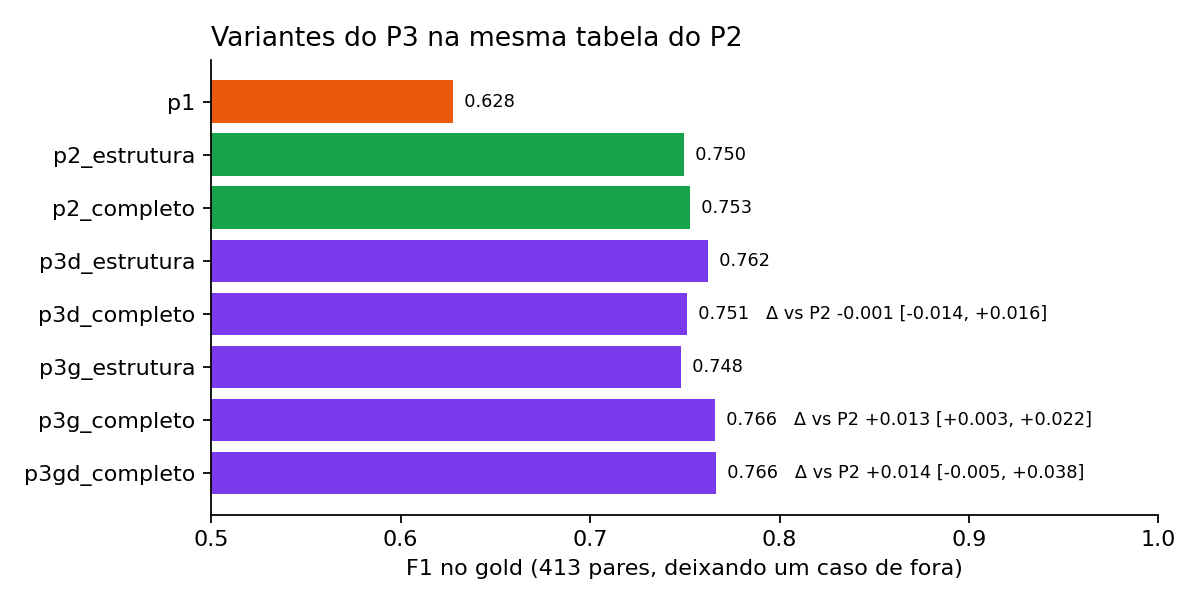

In [10]:
display(tabela("p3_metricas_validacao.csv")[["variante", "precisao", "cobertura", "f1", "tipo_acertado", "casos_vs_p2_V-E-D"]])
display(Image(filename=str(raiz / "assets/images/p3_f1_variantes.png"), width=760))

## 4. P3-D: embeddings de sentença

Cada par vira um texto (as duas entidades e o que há entre elas) e um vetor de 768 números de um modelo biomédico
(`NeuML/pubmedbert-base-embeddings`). Como no `lm_score` do P2, o vetor **não** entra direto na regressão — seriam
768 pesos para 413 exemplos. Ele é comprimido em um número por **empilhamento** (Wolpert, 1992): uma regressão
logística sobre o vetor diz "este par tem relação?", fora de amostra por caso, e essa probabilidade vira o atributo
`emb_score` do P2.

In [11]:
from clinical_kg.hibrido.embeddings import Codificador, texto_do_par

e = next(x for x in gold if x.relacao == "REVEALED_BY")
print("texto do par:", repr(texto_do_par(textos[e.caso], e.chave)))
codificador = Codificador()
print(f"vetores em cache: {len(codificador.cache)} (a primeira execução baixa o modelo e os calcula)")

texto do par: 'Past medical history revealed atrial fibrillation'


vetores em cache: 9325 (a primeira execução baixa o modelo e os calcula)


In [12]:
display(tabela("p3_sensibilidade_embeddings.csv"))

,C_nivel0,f1_p3d_completo,diferenca_vs_p2_completo,ic95_inf,ic95_sup
0,0.1,0.7490,-0.0032,-0.0129,0.0052
1,1.0,0.7510,-0.0011,-0.0137,0.0159
2,10.0,0.7598,0.0072,-0.0150,0.0310


O nível 0 foi fixado **antes** de olhar o gold (C = 1, o padrão do scikit-learn); a tabela mostra que nenhum valor de
C dá um intervalo fora do zero. Com 413 pares, informação léxica densa não supera os atributos estruturais — o mesmo
que o P2 viu com n-gramas como atributos diretos.

## 5. O LLM como anotador de relações (E3 e E4)

Para cada par candidato, o LLM recebe a sentença com as entidades marcadas, a definição **só dos tipos admissíveis**
para as categorias das duas entidades e, no modo few-shot, os exemplos de treino mais parecidos (por embeddings,
nunca do caso de teste). Regras disciplinam a resposta: o tipo tem de ser admissível e a **evidência tem de ser um
trecho literal da sentença**. A confiança é a **autoconsistência** (fração de *k* amostras que concordam), não a que o
modelo declara.

In [13]:
from clinical_kg.llm.anotador import Anotador, descrever_par, interpretar, montar_prompt

causal = next(x for x in gold if x.relacao == "CAUSED_BY")
par = descrever_par(causal, textos[causal.caso])
print(montar_prompt(par))

Relation types:
- TREATED_WITH: a condition (or the patient) is treated with this drug or procedure
- REVEALED_BY: an exam or procedure revealed/showed/confirmed this finding or diagnosis
- CAUSED_BY: one condition is caused by, secondary to or due to the other
- COORDINATE_WITH: the two entities are listed together as siblings (A, B and C)
- NENHUMA: none of the above holds between these two entities in this sentence

Now this one:
Sentence: A 35-year-old male was admitted to intensive care unit through accident/emergency after a road [E1]traffic accident[/E1] and having sustained [E2]multiple injuries[/E2].
E1 = traffic accident (Diagnosis); E2 = multiple injuries (Diagnosis)
Answer with JSON: {"relacao": one of ['TREATED_WITH', 'REVEALED_BY', 'CAUSED_BY', 'COORDINATE_WITH', 'NENHUMA'], "evidencia": the exact words of the sentence that support it ("" for NENHUMA)}


A validação por regras, com respostas inventadas:

In [14]:
trecho = texto_do_par(textos[causal.caso], causal.chave)     # as duas entidades e o que há entre elas
for resposta in [f'{{"relacao": "CAUSED_BY", "evidencia": "{trecho}"}}',
                 '{"relacao": "CAUSED_BY", "evidencia": "due to an infection"}',
                 '{"relacao": "LOCATED_IN", "evidencia": "x"}',
                 'I think it is CAUSED_BY']:
    print(f"{resposta[:70]:<72} -> {interpretar(resposta, par)}")

{"relacao": "CAUSED_BY", "evidencia": "traffic accident and having sus   -> CAUSED_BY
{"relacao": "CAUSED_BY", "evidencia": "due to an infection"}             -> None
{"relacao": "LOCATED_IN", "evidencia": "x"}                              -> None
I think it is CAUSED_BY                                                  -> None


E a autoconsistência, com um provedor falso que responde três vezes `CAUSED_BY`, uma vez outra coisa e uma vez com
evidência inventada (descartada):

In [15]:
import tempfile
from clinical_kg.llm.cache import CacheLLM
from clinical_kg.llm.provedor import ProvedorFalso

evidencia = trecho
respostas = iter([f'{{"relacao": "CAUSED_BY", "evidencia": "{evidencia}"}}'] * 3 +
                 [f'{{"relacao": "COORDINATE_WITH", "evidencia": "{evidencia}"}}',
                  '{"relacao": "CAUSED_BY", "evidencia": "texto inventado"}'])
with tempfile.TemporaryDirectory() as pasta:
    falso = ProvedorFalso(lambda *a: next(respostas), cache=CacheLLM(Path(pasta) / "c.jsonl"))
    print(Anotador(falso, k=5).anotar(par))

{'relacao': 'CAUSED_BY', 'confianca': 0.75, 'votos': {'CAUSED_BY': 3, 'COORDINATE_WITH': 1}, 'validas': 4, 'amostras': 5}


Toda resposta fica em cache (`data/interim/cache/llm_cache.jsonl`, chave = hash do pedido), o que torna os números
reproduzíveis sem chamar o modelo e dá o custo exato de cada variante:

In [16]:
p1, p2 = previsoes["P1"], previsoes["P2 completo"]
discordam = sum(1 for (_, a), (_, b) in zip(p1, p2) if a != b)
pd.DataFrame([("P3-A zero-shot", len(gold)), ("P3-B few-shot", len(gold)), ("P3-B, k = 5", 5 * len(gold)),
              ("P3-C empilhamento (usa os votos do P3-A)", 0), ("P3-E cascata: só onde P1 e P2 discordam", discordam),
              ("P3-F supervisão fraca: os 2.391 candidatos", 2391)], columns=["variante", "chamadas ao LLM"])

,variante,chamadas ao LLM
0,P3-A zero-shot,413
1,P3-B few-shot,413
2,"P3-B, k = 5",2065
3,P3-C empilhamento (usa os votos do P3-A),0
4,P3-E cascata: só onde P1 e P2 discordam,340
5,P3-F supervisão fraca: os 2.391 candidatos,2391


In [17]:
from clinical_kg.llm.cache import CacheLLM
print(f"respostas no cache: {len(CacheLLM())}")
print("Para preencher: python -m clinical_kg.llm.pipeline anotar   (ver README, Demonstração Executável)")
print("Para medir:     python -m clinical_kg.llm.pipeline avaliar  (só lê o cache)")

respostas no cache: 0
Para preencher: python -m clinical_kg.llm.pipeline anotar   (ver README, Demonstração Executável)
Para medir:     python -m clinical_kg.llm.pipeline avaliar  (só lê o cache)


*(a preencher quando o cache existir: a tabela de `p3_metricas_llm.csv`)*

## 6. Paciente Virtual (E6)

O grafo da aplicação vem de **1.920 casos reais de duas fontes**: os 50 do P1, um recorte de 1.674 casos digestivos
do MultiCaRe completo e os **200 relatos do MACCROBAT** (a segunda fonte, aqui no seu quarto uso: complemento da
aplicação), todos passados pelo P1 e pelo modelo final do P3 (`make p3-corpus`). Do grafo saem os **perfis de diagnóstico**:
para cada diagnóstico, o que os pacientes reais que o têm apresentam, com a frequência e os casos de cada fato.

In [18]:
from clinical_kg.paciente.corpus import carregar
from clinical_kg.paciente.perfil import montar_perfis

corpus = carregar(["digestivo", "multicare50", "maccrobat"])
perfis = montar_perfis(corpus, minimo_casos=3)
print(f"{len(corpus.casos)} casos reais, {len(perfis)} perfis de diagnóstico (≥ 3 pacientes cada)")
de_mac = [p for p in perfis.values() if any(c.startswith("MACCROBAT_") for c in p.casos)]
print(f"{len(de_mac)} perfis têm pacientes do MACCROBAT, por exemplo:",
      sorted(((p.nome, sum(c.startswith('MACCROBAT_') for c in p.casos)) for p in de_mac), key=lambda t: -t[1])[:5])
perfil = next(p for p in perfis.values() if p.nome == "acute pancreatitis")
n = len(perfil.casos)
pd.DataFrame([{"fato": f.nome, "categoria": f.categoria, "pacientes": f"{len(f.casos)}/{n}",
               "ligado ao dx no grafo": "sim" if f.ligado else ""} for f in perfil.ordenados()[:12]])

1920 casos reais, 134 perfis de diagnóstico (≥ 3 pacientes cada)
46 perfis têm pacientes do MACCROBAT, por exemplo: [('hypertension', 6), ('heart failure', 6), ('dysphagia', 5), ('rash', 4), ('adenocarcinoma', 3)]


,fato,categoria,pacientes,ligado ao dx no grafo
0,lipase,Exam,5/9,
1,ultrasonography,Exam,5/9,
2,ercp,Exam,3/9,sim
3,abdominal pain,Symptom,3/9,
4,amylase,Exam,3/9,
5,epigastric pain,Symptom,3/9,
6,tachypnea,Finding,3/9,
7,vomiting,Symptom,3/9,
8,calcium,Exam,2/9,
9,chest x-ray,Exam,2/9,


A **ficha** é uma amostra do perfil: fatos típicos sempre; fatos raros e sintomas **negados** (frequentes nos
diagnósticos concorrentes e ausentes deste) conforme a dificuldade. Ela é o gold do paciente virtual *por
construção*: tudo o que o paciente diz sai dela, e cada item aponta para os casos reais que o sustentam.

In [19]:
from clinical_kg.paciente.ficha import concorrentes, montar_ficha
from clinical_kg.paciente.narrador import NarradorModelo

print("Concorrentes no grafo:", [(o.nome, round(s, 2)) for o, s in concorrentes(perfil, perfis, 4)], "\n")
narrador = NarradorModelo()
for dificuldade in ("facil", "medio", "dificil"):
    ficha = montar_ficha(perfil, perfis, dificuldade, semente=3, nomes=corpus.nomes)
    print(f"[{dificuldade}] {narrador.completo(ficha)}\n")

Concorrentes no grafo: [('pancreatic pseudocyst', 0.53), ('pancreatitis', 0.52), ('leukocytosis', 0.43), ('hypercalcemia', 0.39)] 

[facil] A 63-year-old woman presented with vomiting, abdominal pain and epigastric pain. Physical examination revealed tachypnea. Lipase revealed 138 U/L and 25 U/L. Ultrasonography was performed. ERCP was performed. The diagnosis of acute pancreatitis was made. She was treated with hemodialysis and resection.

[medio] A 34-year-old woman presented with epigastric pain, vomiting and upper abdominal pain. She denied epigastric discomfort. Physical examination revealed tachypnea. Lipase revealed 1572 U/l. Ultrasonography was performed. ERCP was performed. The diagnosis of acute pancreatitis was made. She was treated with hemodialysis and resection.

[dificil] A 35-year-old woman presented with vomiting, dyspnea and weakness. She denied epigastric discomfort and fatigue. Physical examination revealed tachypnea. Lipase revealed 227 U/L. Ultrasonography was per

O atendimento responde só com a ficha; o feedback compara com o diferencial que o grafo calcula com os mesmos fatos:

In [20]:
from clinical_kg.paciente.dialogo import Atendimento
from clinical_kg.paciente.feedback import avaliar

ficha = montar_ficha(perfil, perfis, "medio", semente=3, nomes=corpus.nomes)
at = Atendimento(ficha)
print("apresentação:", narrador.apresentacao(ficha))
for resposta in (at.queixa_principal(), at.perguntar("Do you have any fever?"),
                 at.perguntar(f"Do you have {ficha.negados()[0].nome}?"), at.pedir_exame(ficha.de('Exam')[0].nome)):
    print("  paciente:", resposta.texto)
r = avaliar(ficha, at, perfil.cui, perfis)
print(f"\nhipótese certa: {r['correto']}; com o que foi levantado, o grafo põe o diagnóstico em {r['posicao_do_certo']}º")
pd.DataFrame(r["diferencial"])[["nome", "probabilidade", "casos"]].round(3)

apresentação: A 34-year-old woman presented with epigastric pain, vomiting and upper abdominal pain.
  paciente: I've been having epigastric pain, vomiting and upper abdominal pain.
  paciente: No, I haven't noticed anything like that.
  paciente: No, I don't have epigastric discomfort.
  paciente: lipase: 1572 U/l.

hipótese certa: True; com o que foi levantado, o grafo põe o diagnóstico em 1º


,nome,probabilidade,casos
0,acute pancreatitis,0.135,9
1,pancreatic pseudocyst,0.047,3
2,peptic ulcer disease,0.046,4
3,pancreatitis,0.037,6
4,pulmonary tuberculosis,0.028,3
5,hypoalbuminemia,0.028,6


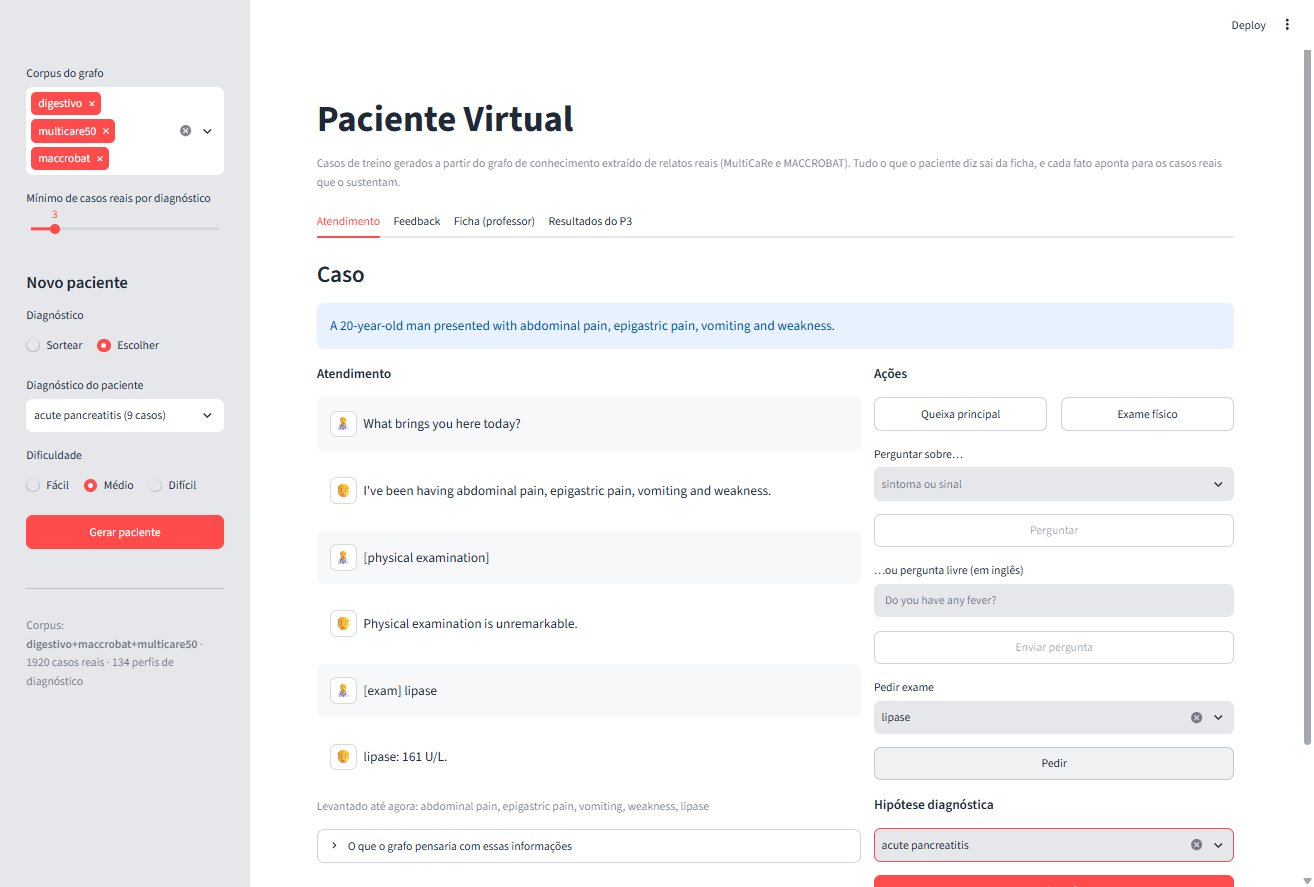

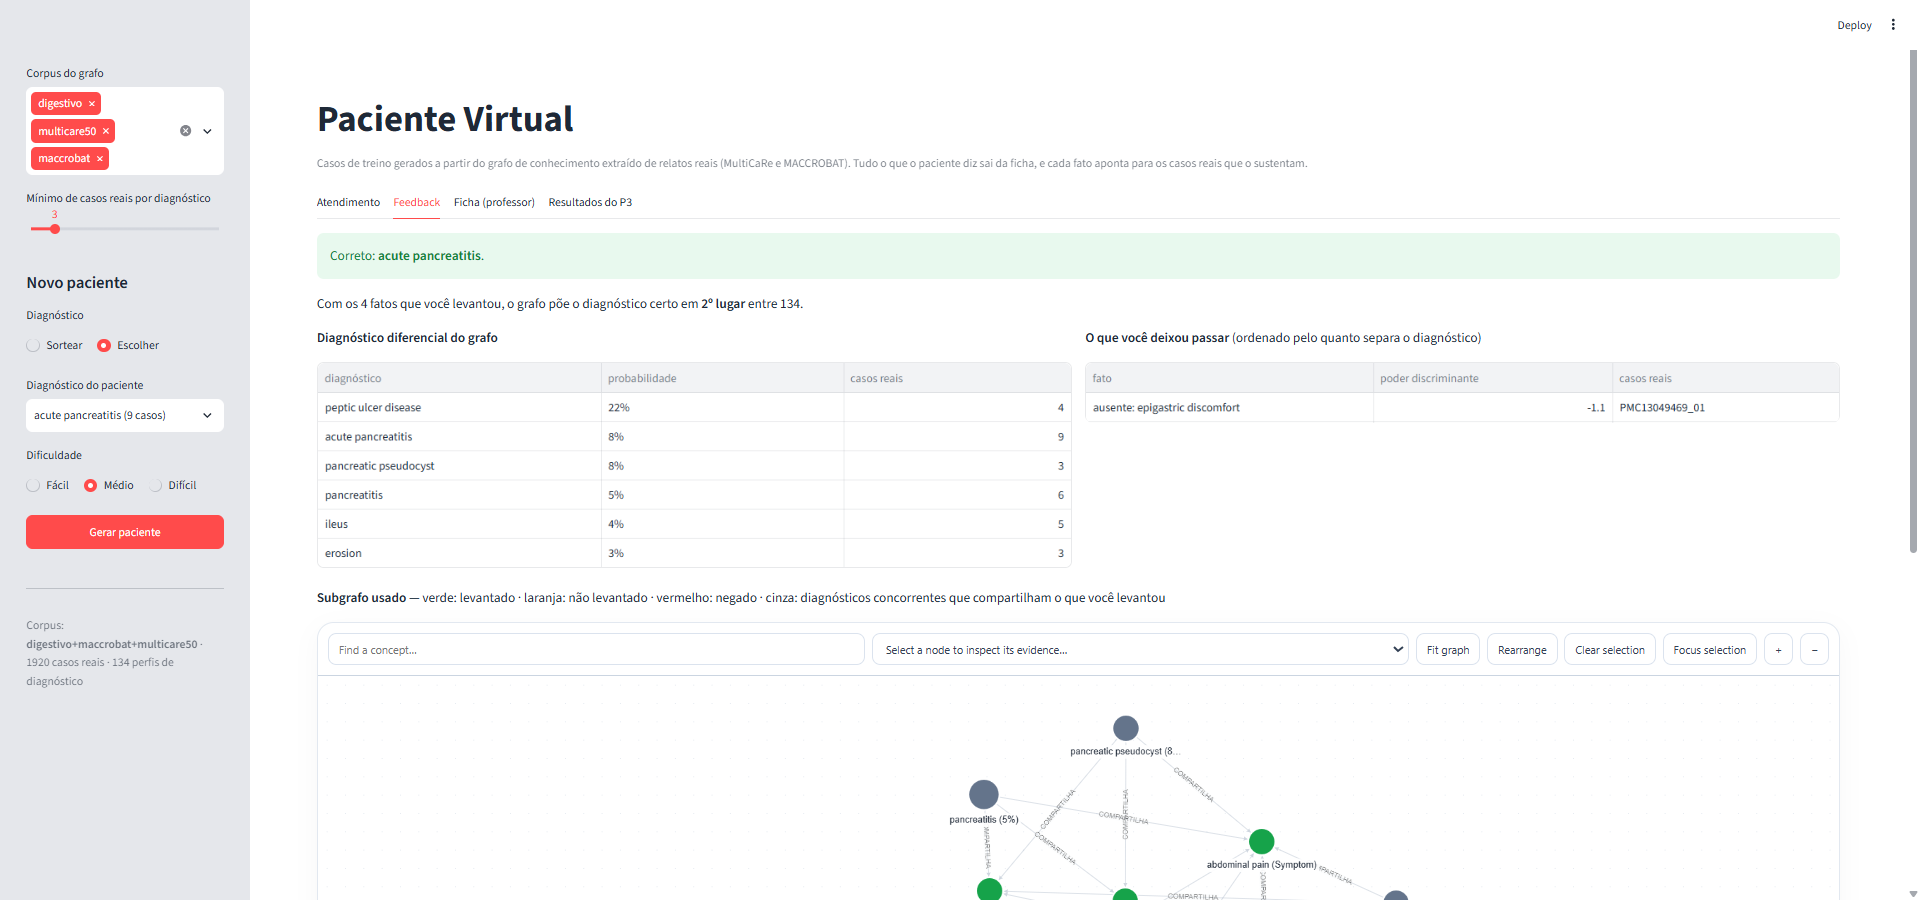

In [21]:
display(Image(filename=str(raiz / "assets/images/p3_app_atendimento.png"), width=900))
display(Image(filename=str(raiz / "assets/images/p3_app_feedback.png"), width=900))

A aplicação: `make app-p3` (ou `streamlit run src/clinical_kg/app/projeto3.py`). Não precisa do gazetteer nem de LLM.

## 7. Ida e volta: o texto gerado volta aos extratores

O caso narrado é reextraído (entidades e asserção do P1; relações pelas regras do P1, pelo modelo do P2 e pelo do
P3). Como a ficha é o gold, mede-se a **fidelidade** (fatos recuperados com a polaridade certa), a **alucinação** do
extrator e as **relações** recuperadas — uma avaliação sem custo de anotação, num texto de outra distribuição.

In [22]:
if TEM_UMLS:
    from clinical_kg.paciente.ida_volta import Extratores, medir as medir_ida_volta
    texto = narrador.completo(montar_ficha(perfil, perfis, "dificil", semente=3, nomes=corpus.nomes))
    print(texto, "\n")
    m = medir_ida_volta(montar_ficha(perfil, perfis, "dificil", semente=3, nomes=corpus.nomes), texto, Extratores())
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in m.items()})
else:
    print("(sem o gazetteer: veja o resumo gravado abaixo)")

A 35-year-old woman presented with vomiting, dyspnea and weakness. She denied epigastric discomfort and fatigue. Physical examination revealed tachypnea. Lipase revealed 227 U/L. Ultrasonography was performed. The diagnosis of acute pancreatitis was made. She was treated with hemodialysis and resection. 



{'dx': 'acute pancreatitis', 'dificuldade': 'dificil', 'fatos': 11, 'fidelidade': 0.909, 'erro_polaridade': 0.091, 'fidelidade_p3': 1.0, 'erro_polaridade_p3': 0.0, 'conceitos_extraidos': 11, 'alucinacao': 0.0, 'relacoes_esperadas': 7, 'rel_p1': 0.714, 'par_p1': 0.857, 'rel_p2': 0.857, 'par_p2': 0.857, 'rel_p3': 0.857, 'par_p3': 0.857}


,dificuldade,fichas,fidelidade,erro_polaridade,fidelidade_p3,erro_polaridade_p3,alucinacao,rel_p1,rel_p2,rel_p3,par_p1
0,dificil,134,0.9177,0.0699,0.9876,0.0,0.0076,0.6398,0.8033,0.8033,0.8033
1,facil,134,0.9883,0.0000,0.9883,0.0,0.0062,0.6109,0.8219,0.8219,0.8219
2,medio,134,0.9900,0.0000,0.9900,0.0,0.0062,0.6218,0.8193,0.8193,0.8193
3,todas,402,0.9653,0.0233,0.9886,0.0,0.0067,0.6242,0.8148,0.8148,0.8148


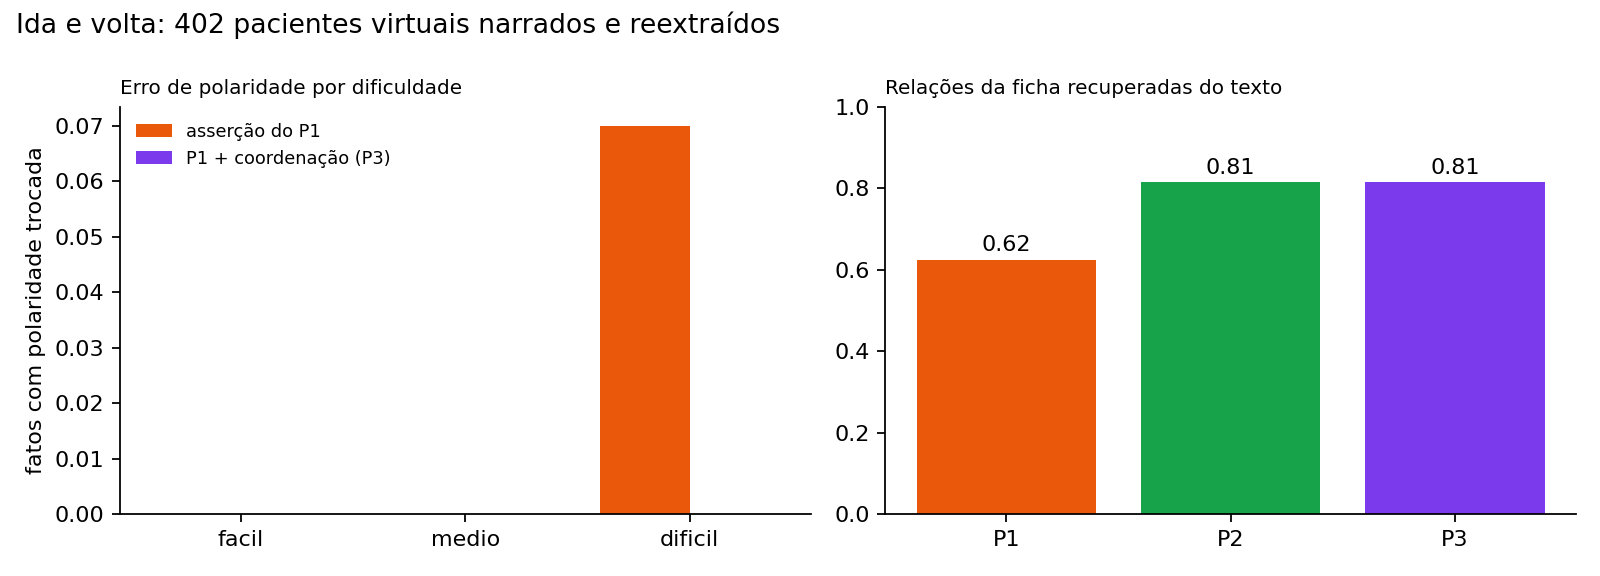

In [23]:
resumo_iv = tabela("p3_ida_volta_resumo.csv")
display(resumo_iv[["dificuldade", "fichas", "fidelidade", "erro_polaridade", "fidelidade_p3", "erro_polaridade_p3",
                   "alucinacao", "rel_p1", "rel_p2", "rel_p3", "par_p1"]])
display(Image(filename=str(raiz / "assets/images/p3_ida_volta.png"), width=860))

O erro de polaridade do P1 aparece **só no nível difícil** — o único com sintomas negados. Lendo as fichas com erro:

In [24]:
from clinical_kg.hibrido.assercao import propagar_coordenacao

frase = "She denied tenderness, dysuria and chest pain."
ents = [{"start": frase.index(w), "end": frase.index(w) + len(w)} for w in ("tenderness", "dysuria", "chest pain")]
estados_p1 = ["negated", "affirmed", "affirmed"]   # o que o escopo do P1 devolve nesta frase
print("P1          :", list(zip([frase[e['start']:e['end']] for e in ents], estados_p1)))
print("P1 + coord. :", list(zip([frase[e['start']:e['end']] for e in ents], propagar_coordenacao(frase, ents, estados_p1))))

P1          : [('tenderness', 'negated'), ('dysuria', 'affirmed'), ('chest pain', 'affirmed')]
P1 + coord. : [('tenderness', 'negated'), ('dysuria', 'negated'), ('chest pain', 'negated')]


O escopo de negação do P1 reinicia a cada oração, e o segmentador corta a oração na conjunção: em uma lista
coordenada, só a primeira entidade sai negada. A correção é uma regra de dez linhas aplicada **depois** do P1
(`hibrido/assercao.py`): uma entidade separada da anterior só por coordenação herda a negação dela. Nas fichas, a
polaridade trocada vai a zero. Mas a prova que importa é em dados reais, que a correção nunca viu — o MACCROBAT,
anotado por humanos:

In [25]:
from clinical_kg.maccrobat.avaliacao import avaliar_assercao

assercao, _ = avaliar_assercao(documentos)
pd.DataFrame(assercao)[["decisor", "classe", "anotadas", "precisao", "cobertura", "f1", "dif_f1_vs_p1_ic95"]].round(3)

,decisor,classe,anotadas,precisao,cobertura,f1,dif_f1_vs_p1_ic95
0,p1,negated,1004,0.623,0.537,0.577,
1,p1,hedged,217,0.250,0.189,0.215,
2,p3,negated,1004,0.601,0.657,0.628,"+0.0508 [+0.0306, +0.0718]"
3,p3,hedged,217,0.244,0.217,0.229,


A F1 da negação sobe de 0,577 para 0,628, com intervalo (bootstrap por documento) inteiro acima de zero. É o ciclo
grafo → texto → grafo fazendo o que prometia: um texto com gold por construção revelou um erro que o gold de 413
pares nunca mostrou, e a correção generalizou para dados reais.

## 8. O grafo do P3 nos 50 casos

In [26]:
tabela("p3_comparacao_arestas.csv")[["relacao", "p1", "p2", "p3", "jaccard_p2_p3", "jaccard_p1_p3"]]

,relacao,p1,p2,p3,jaccard_p2_p3,jaccard_p1_p3
0,CAUSED_BY,35,31,15,0.000,0.064
1,COORDINATE_WITH,185,427,429,0.959,0.282
2,HAS_DIAGNOSIS,189,101,100,0.990,0.290
3,HAS_FINDING,184,110,110,1.000,0.246
4,HAS_SYMPTOM,55,39,39,1.000,0.424
5,LOCATED_IN,239,259,322,0.674,0.424
6,REVEALED_BY,196,234,261,0.847,0.169
7,TREATED_WITH,269,241,242,0.980,0.310
8,TOTAL,1352,1442,1518,0.859,0.289


O P3 muda sobretudo onde recebeu julgamentos novos: `LOCATED_IN` (+63 arestas) e `CAUSED_BY`, que troca
inteiramente. O modelo lógico do grafo:

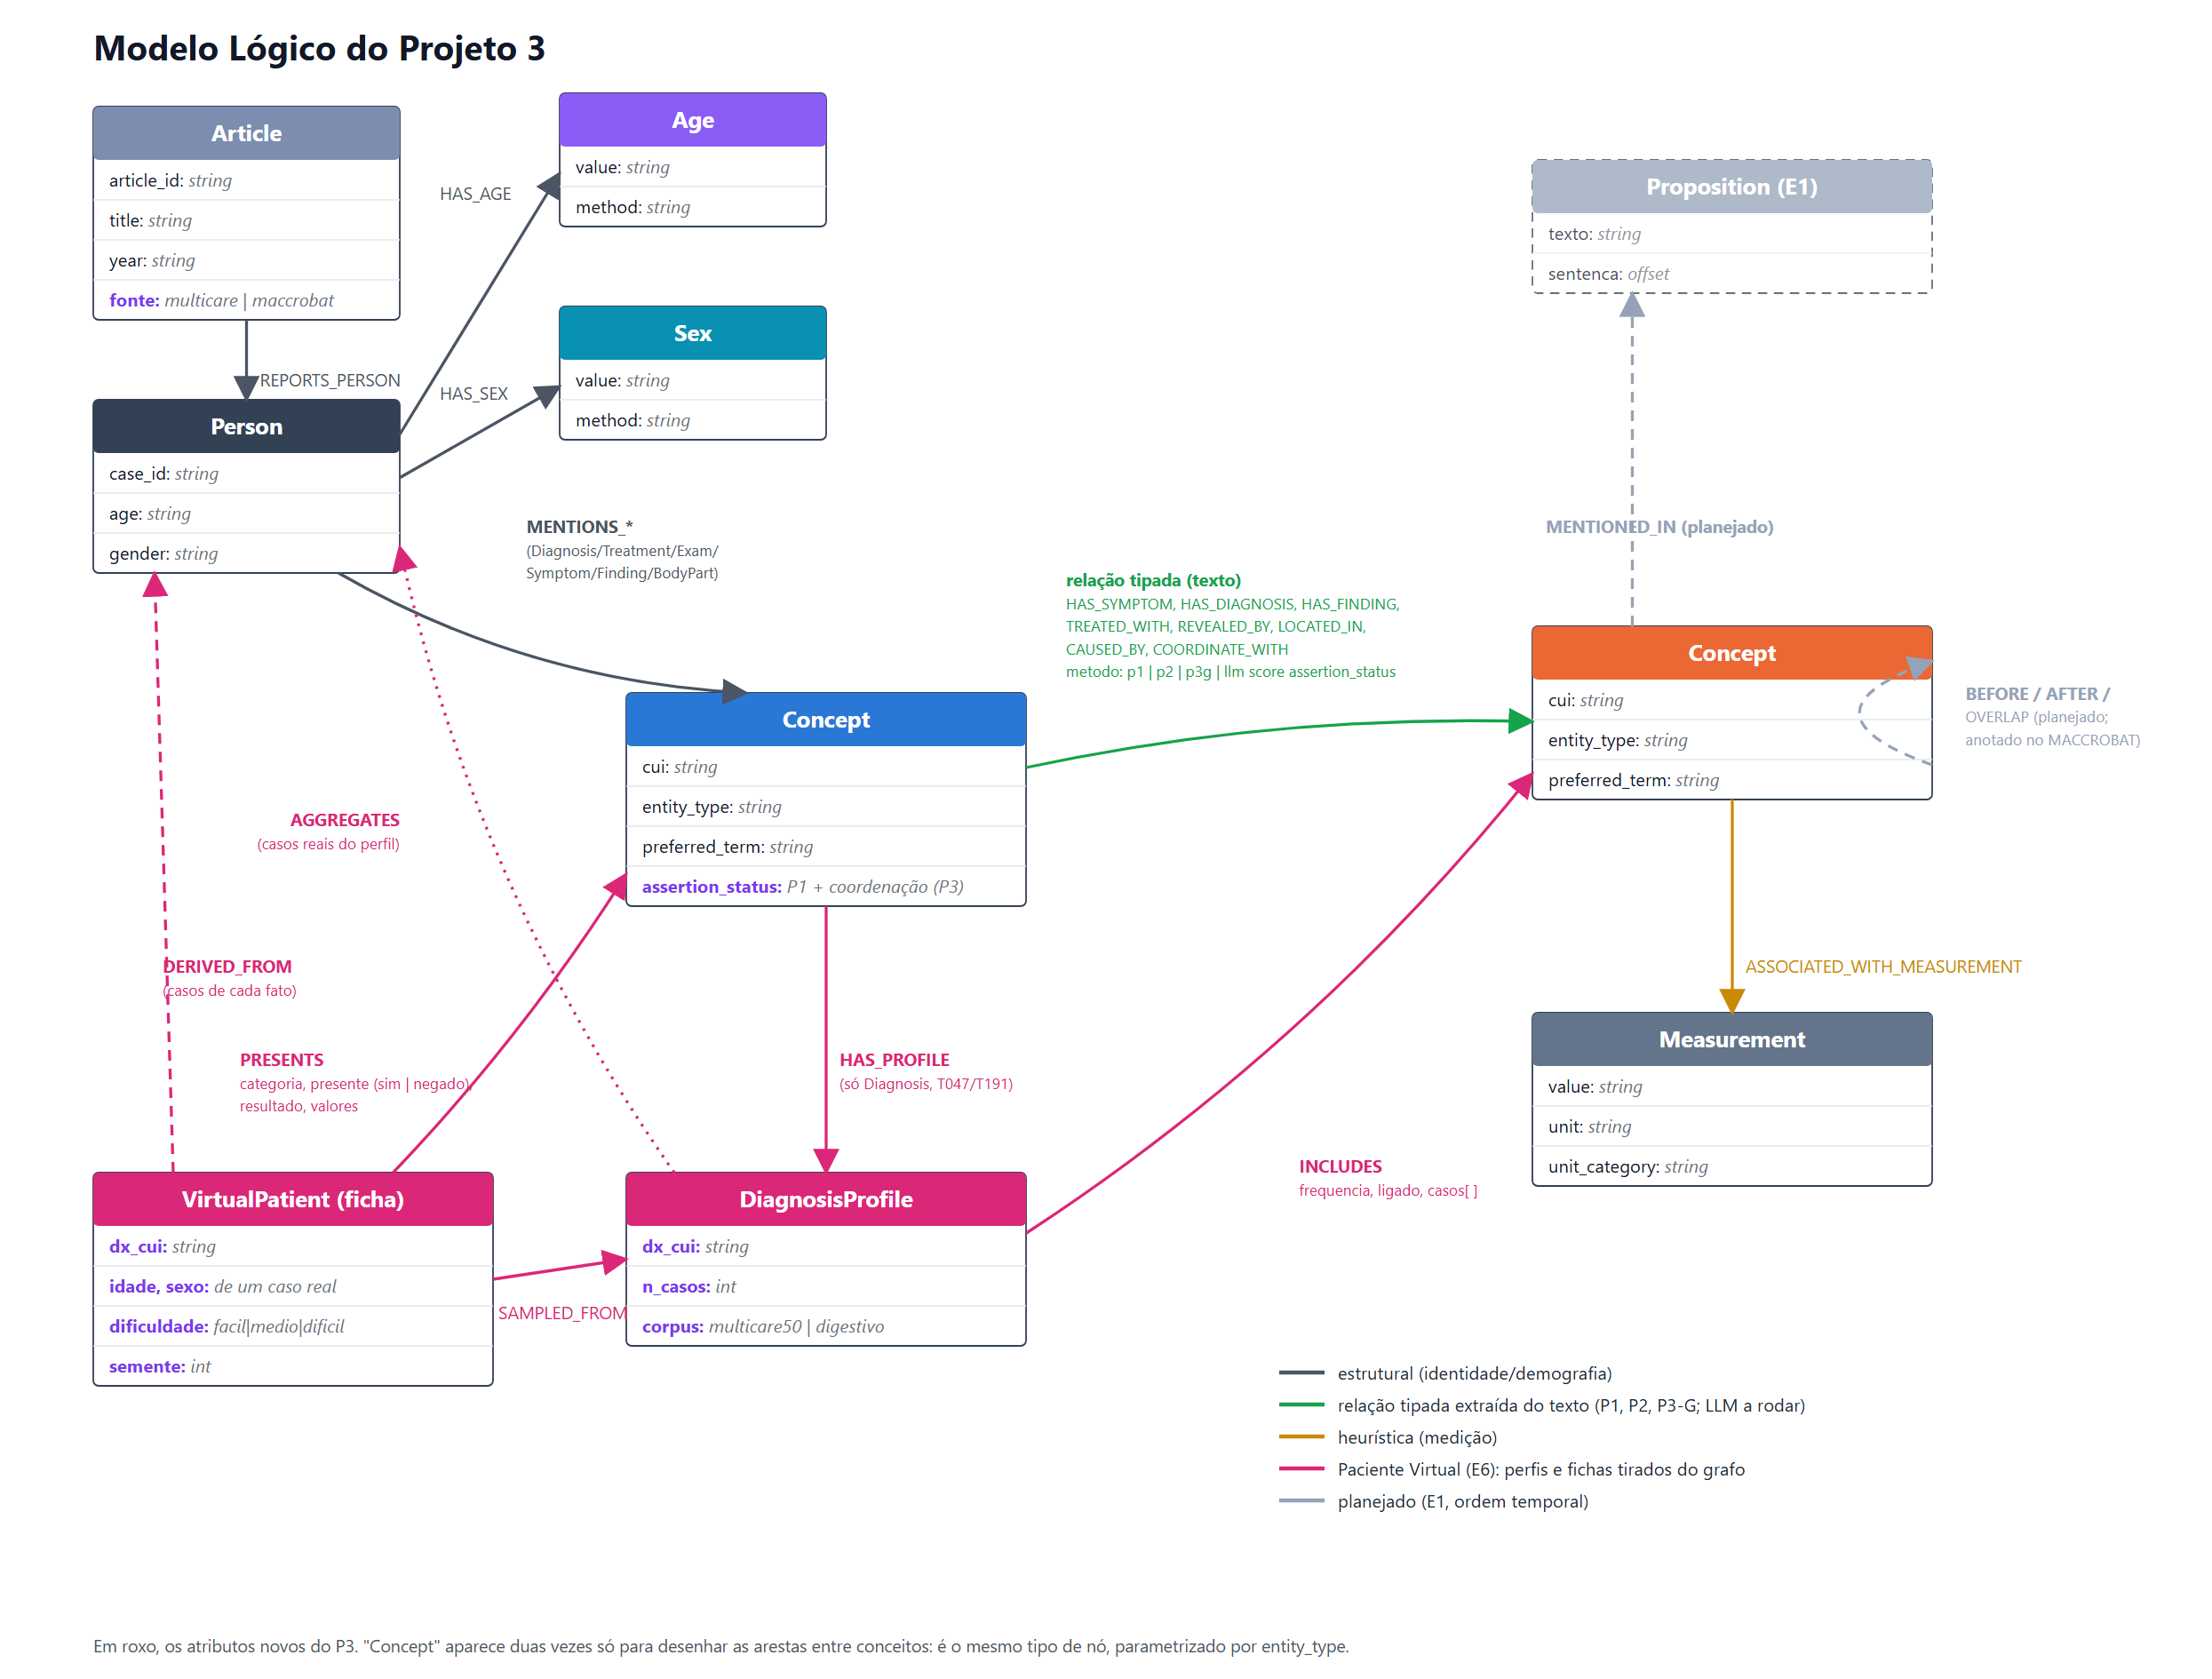

In [27]:
display(Image(filename=str(raiz / "assets/images/modelo_logico_p3.png"), width=900))

## Conclusões (sem LLM)

* **A hipótese do P2 se confirma em parte.** Mais julgamentos humanos, de outro corpus, melhoram o classificador
  (P3-G, +0,013 com intervalo acima de zero) — mas só onde os atributos conseguem expressar o padrão (`LOCATED_IN`).
  `CAUSED_BY` não é aprendida nem com 149 exemplos: falta léxico, não exemplos.
* **Embeddings densos não ajudam** com 413 pares (P3-D), como os n-gramas diretos no P2.
* **O gargalo fora do MultiCaRe é reconhecer entidades** (F1 0,49 no MACCROBAT), não decidir relações.
* **O grafo serve para gerar pacientes virtuais fiéis**: 98,9% dos fatos da ficha voltam do texto, com 0,7% de
  conceitos fora da ficha.
* **A ida e volta é uma ferramenta de depuração**: achou um erro de negação do P1 cuja correção vale +0,051 de F1 em
  dados humanos externos.

As variantes com LLM (P3-A, B, C, E, F) estão implementadas e testadas; os números entram quando o cache de
respostas for preenchido.